In [1]:
import sys; sys.path.append("..")
import time, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from src.data import load_data
from src.config import RANDOM_STATE
from src.pipelines import get_advanced
from src.experiment_log import ExperimentLogger

X_train, _, y_train, _, labels = load_data()

# Chi chia nho TAP TRAIN de do thoi gian, khong dung de chon mo hinh
Xa, Xb, ya, yb = train_test_split(X_train, y_train, test_size=0.2,
                                  stratify=y_train, random_state=RANDOM_STATE)

for name, m in get_advanced().items():
    t0 = time.time(); m.fit(Xa, ya); ft = time.time() - t0
    f1 = f1_score(yb, m.predict(Xb), average="macro")
    print(f"{name}: fit {ft:.1f}s, macro-F1 {f1:.4f}, uoc tinh CV 5-fold ~ {5*ft/60:.1f} phut")

mlp_64: fit 10.4s, macro-F1 0.9331, uoc tinh CV 5-fold ~ 0.9 phut
hgb_default: fit 7.6s, macro-F1 0.0816, uoc tinh CV 5-fold ~ 0.6 phut


In [2]:
lg = ExperimentLogger("thai")
for name, model in get_advanced().items():
    lg.run(model, X_train, y_train, name, notes="tham so mac dinh")

In [3]:
from src.pipelines import get_xgb
from src.experiment_log import ExperimentLogger

lg = ExperimentLogger("bao")
for name, model in get_xgb().items():
    lg.run(model, X_train, y_train, name, notes="tham so mac dinh")

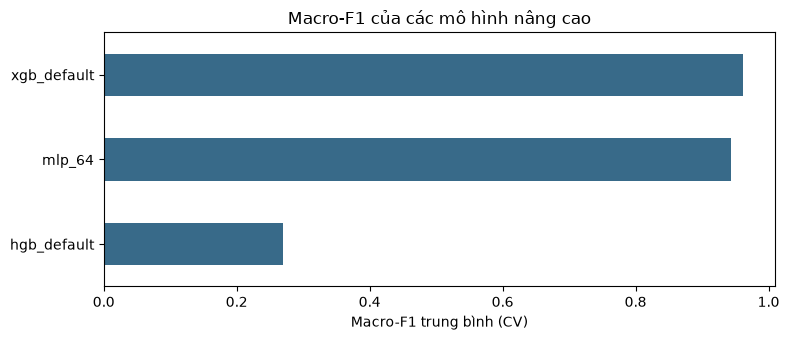

In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

results = (Path('..') if Path.cwd().name == 'experiments' else Path('.')) / 'results'
models = ['mlp_64', 'hgb_default', 'xgb_default']
values = pd.concat([pd.read_csv(results / f'cv/{name}.csv') for name in models]).groupby('model')['macro_f1'].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
values.sort_values().plot.barh(ax=ax, color='#386A89')
ax.set(title='Macro-F1 của các mô hình nâng cao', xlabel='Macro-F1 trung bình (CV)', ylabel='')
fig.tight_layout()
(results / 'figures').mkdir(exist_ok=True)
fig.savefig(results / 'figures/advanced_models_macro_f1.png', dpi=300, bbox_inches='tight')
plt.show()